### STEP 1 IMPORTING NECESSARY LIBRARIES

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, 
                             classification_report, roc_curve, auc)
print("Imported")

Imported


### STEP 2: IMPORTING DATASET

In [6]:
data=pd.read_csv('Social_Network_Ads.csv')
print(data.head())

   Age  EstimatedSalary  Purchased
0   19            19000          0
1   35            20000          0
2   26            43000          0
3   27            57000          0
4   19            76000          0


### STEP 3: VISUALISING DATA

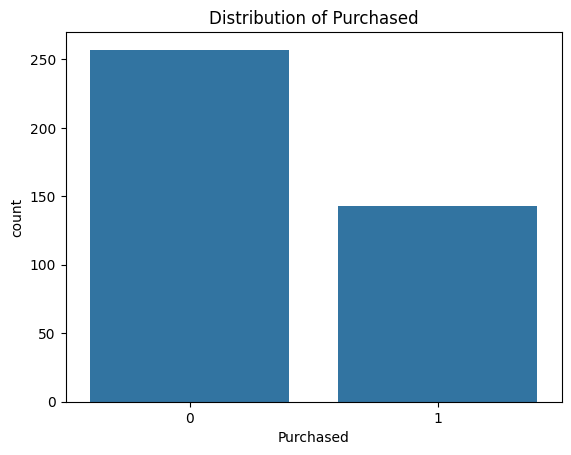

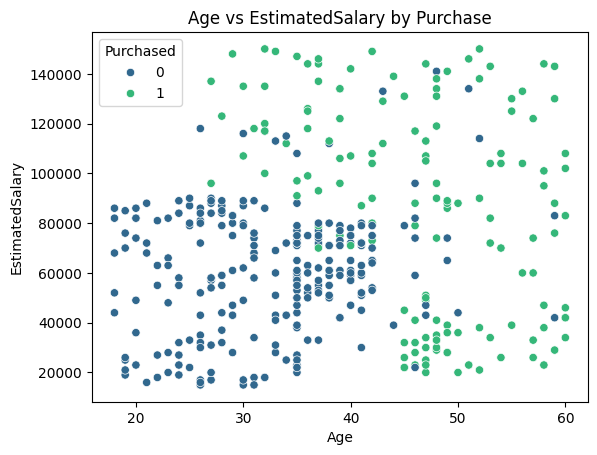

In [9]:
sns.countplot(x="Purchased", data=data)
plt.title("Distribution of Purchased")
plt.show()

sns.scatterplot(x="Age", y="EstimatedSalary", hue="Purchased", data=data, palette="viridis")
plt.title("Age vs EstimatedSalary by Purchase")
plt.show()

### STEP 4: SEPERATING DATA

In [10]:
x=data[["Age","EstimatedSalary"]]
y=data["Purchased"]
print(y.head())
print(x.head())

0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64
   Age  EstimatedSalary
0   19            19000
1   35            20000
2   26            43000
3   27            57000
4   19            76000


### STEP 5: SPLITTING OF DATA

In [11]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

### STEP 6: FEATURE SCALING TO MENTAIN DIFFERENT DATA SCALES

In [12]:
scaler=StandardScaler()
xtrain=scaler.fit_transform(xtrain)
xtest = scaler.transform(xtest)
print(xtest[:5])
print(xtrain[:5])

[[ 1.01747806  1.38657661]
 [-1.0468002  -1.60481906]
 [-0.20232273 -1.46100196]
 [ 0.07916976  1.18523267]
 [-1.60978518  0.32233007]]
[[-1.23446186 -0.367992  ]
 [-0.57764605 -1.05831408]
 [ 0.07916976  0.26480323]
 [ 1.95578636 -1.3747117 ]
 [ 0.36066225 -0.31046516]]


### STEP 7:TRAINING OUR MODEL

In [13]:
model=LogisticRegression(random_state=42)
model.fit(xtrain,ytrain)

LogisticRegression(random_state=42)

### STEP 8: PREDICTING THE TESTING DATA

In [46]:
ypred=model.predict(xtest)
yprob=model.predict_proba(xtest)[:, 1]


### EVALUATING The Model

In [41]:
accuracy=accuracy_score(ytest,ypred)
print(accuracy)
print(f"Accuracy: {accuracy * 100:.2f}%")

0.8375
Accuracy: 83.75%


### STEP 9: CREATING CONFUSION MATRIX

In [43]:
cm = confusion_matrix(ytest, ypred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[48  3]
 [10 19]]


### STEP-9 CLASSIFICATION REPORT

In [44]:
print("Classification Report:")
print(classification_report(ytest, ypred, target_names=["Not Purchased", "Purchased"]))


Classification Report:
               precision    recall  f1-score   support

Not Purchased       0.83      0.94      0.88        51
    Purchased       0.86      0.66      0.75        29

     accuracy                           0.84        80
    macro avg       0.85      0.80      0.81        80
 weighted avg       0.84      0.84      0.83        80



### ROC AND AUC CURVE

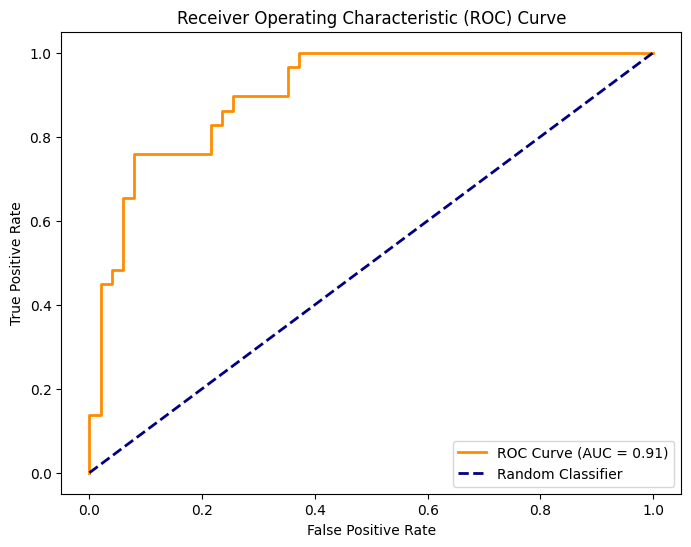

In [47]:
fpr, tpr, thresholds = roc_curve(ytest, yprob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.show()
